In [4]:
# Step 1: Load and Prepare the Data
#First, I will load my Sleep Debt dataset and check its size, columns, missing values, and duplicate rows.

In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('/content/bedtime_screentime_sleep_debt.csv')

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())


Dataset loaded successfully!
Rows and columns: (8500, 18)


,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0.0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92.0,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45.0,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97.0,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0.0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt



Column names:
['user_id', 'age', 'gender', 'occupation_type', 'chronotype', 'bedtime_phone_minutes', 'primary_bedtime_app', 'screen_brightness_pct', 'blue_light_filter_active', 'caffeine_post_5pm_mg', 'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours', 'deep_sleep_pct', 'rem_sleep_pct', 'morning_alarm_snoozes', 'next_day_fatigue_score', 'sleep_debt_category']

Missing values:
user_id                      0
age                          0
gender                       0
occupation_type              0
chronotype                   0
bedtime_phone_minutes        0
primary_bedtime_app         26
screen_brightness_pct        0
blue_light_filter_active     0
caffeine_post_5pm_mg        21
physical_activity_min        0
sleep_latency_min           22
total_sleep_hours            0
deep_sleep_pct               0
rem_sleep_pct                0
morning_alarm_snoozes        0
next_day_fatigue_score       0
sleep_debt_category          0
dtype: int64

Duplicate rows: 0


In [6]:
#Handling Missing Values and Duplicates
# Remove duplicate rows
# Fill missing numerical values with median
# Fill missing categorical values with mode

In [7]:

#Duplication handle.
df = df.drop_duplicates()
#Missing:
df['caffeine_post_5pm_mg'] = df['caffeine_post_5pm_mg'].fillna(df['caffeine_post_5pm_mg'].median())
df['sleep_latency_min'] = df['sleep_latency_min'].fillna(df['sleep_latency_min'].median())

df['primary_bedtime_app'] = df['primary_bedtime_app'].fillna(
    df['primary_bedtime_app'].mode()[0]
)

print("Missing values after cleaning:")
print(df.isnull().sum().sum())

print("Dataset shape after cleaning:", df.shape)


Missing values after cleaning:
0
Dataset shape after cleaning: (8500, 18)


In [8]:
#Target Class Distribution
#The target variable is sleep_debt_category.


sleep_debt_category
Moderate Debt        4462
Mild Deficit         2004
Optimal Recovery     1387
Severe Sleep Debt     647
Name: count, dtype: int64

Class percentages:
sleep_debt_category
Moderate Debt        52.49
Mild Deficit         23.58
Optimal Recovery     16.32
Severe Sleep Debt     7.61
Name: proportion, dtype: float64


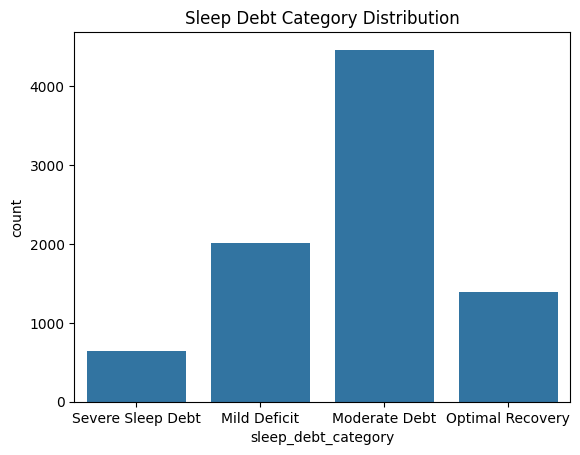

In [9]:

print(df['sleep_debt_category'].value_counts())

print("\nClass percentages:")
print((df['sleep_debt_category'].value_counts(normalize=True) * 100).round(2))

sns.countplot(data=df, x='sleep_debt_category')
plt.title('Sleep Debt Category Distribution')
plt.show()


In [10]:
#Encoding, Train-Test Split, and Scaling
#Convert categorical features into numerical values using one-hot encoding and separate the target variable from the input features.
#Spliting the data into 80% training data and 20% testing data using stratification.
#Finally,using StandardScaler, fitting it only on the training data to avoid data leakage.

In [11]:
df = df.drop(columns=['user_id'])
# Separate features and target
X = df.drop(columns=['sleep_debt_category'])
y = df['sleep_debt_category']

# Convert text columns into numbers
X = pd.get_dummies(X, drop_first=False, dtype=int)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Number of features:", X_train.shape[1])
print("Training target distribution:")
print(y_train.value_counts())


Training rows: 6800
Testing rows: 1700
Number of features: 29
Training target distribution:
sleep_debt_category
Moderate Debt        3569
Mild Deficit         1603
Optimal Recovery     1110
Severe Sleep Debt     518
Name: count, dtype: int64


In [12]:
#Target Leakage Investigation
#First, I will inspect the Decision Tree trained on the original features to identify dominant features.

from sklearn.tree import DecisionTreeClassifier, export_text

diagnostic_tree = DecisionTreeClassifier(max_depth=3, random_state=42)
diagnostic_tree.fit(X_train, y_train)

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": diagnostic_tree.feature_importances_
}).sort_values(by="Importance", ascending=False)

display(feature_importance.head(15))

print(export_text(diagnostic_tree, feature_names=list(X_train.columns)))


,Feature,Importance
7,total_sleep_hours,0.794171
11,next_day_fatigue_score,0.205829
2,screen_brightness_pct,0.000000
1,bedtime_phone_minutes,0.000000
0,age,0.000000
4,caffeine_post_5pm_mg,0.000000
3,blue_light_filter_active,0.000000
6,sleep_latency_min,0.000000
5,physical_activity_min,0.000000
8,deep_sleep_pct,0.000000


|--- total_sleep_hours <= 6.74
|   |--- next_day_fatigue_score <= 8.55
|   |   |--- class: Moderate Debt
|   |--- next_day_fatigue_score >  8.55
|   |   |--- total_sleep_hours <= 5.45
|   |   |   |--- class: Severe Sleep Debt
|   |   |--- total_sleep_hours >  5.45
|   |   |   |--- class: Moderate Debt
|--- total_sleep_hours >  6.74
|   |--- total_sleep_hours <= 7.74
|   |   |--- class: Mild Deficit
|   |--- total_sleep_hours >  7.74
|   |   |--- class: Optimal Recovery



In [13]:
#Remove suspected target leakage features
#These features may be used directly or indirectly to create sleep_debt_category.
#I will exclude them from prediction and compare models using the remaining features.

suspected_leakage_features = [
    'total_sleep_hours',
    'sleep_latency_min',
    'deep_sleep_pct',
    'next_day_fatigue_score'
]

features_to_remove = [col for col in suspected_leakage_features if col in df.columns]
print("Features removed:", features_to_remove)

df_model = df.drop(columns=features_to_remove)

# Separate features and target
X = df_model.drop(columns=['sleep_debt_category'])
y = df_model['sleep_debt_category']

# Convert text columns into numbers
X = pd.get_dummies(X, drop_first=False, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Number of features after leakage removal:", X_train.shape[1])


Features removed: ['total_sleep_hours', 'sleep_latency_min', 'deep_sleep_pct', 'next_day_fatigue_score']
Training rows: 6800
Testing rows: 1700
Number of features after leakage removal: 25


In [14]:
#Step 2: K-Nearest Neighbors (KNN)
#First i will train a KNN model using 5 neighbors.

In [15]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

print("KNN training accuracy (K=5):", knn.score(X_train_scaled, y_train))


KNN training accuracy (K=5): 0.7672058823529412


In [16]:
#Then we will test odd values of K from 1 to 15, compare their accuracies, and select the best K.

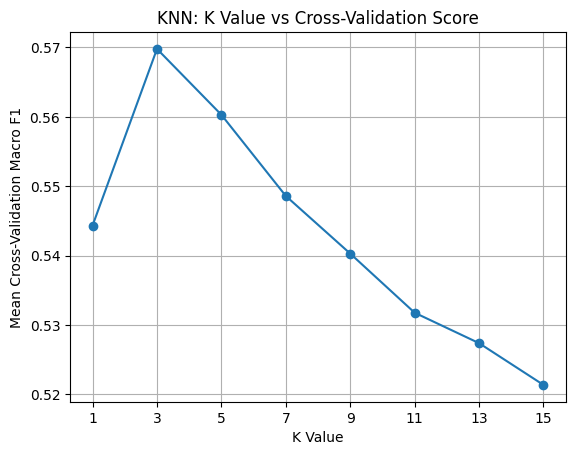

Best K: 3
Best Cross-Validation Macro F1: 0.5697918163071669


In [17]:
#Then we will test odd values of K from 1 to 15, compare their cross-validation scores, and select the best K.

from sklearn.model_selection import GridSearchCV, StratifiedKFold

k_values = list(range(1, 16, 2))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

knn_search = GridSearchCV(
    KNeighborsClassifier(),
    param_grid={'n_neighbors': k_values},
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1
)
knn_search.fit(X_train_scaled, y_train)

k_cv_scores = knn_search.cv_results_['mean_test_score']
plt.plot(k_values, k_cv_scores, marker='o')
plt.xlabel('K Value')
plt.ylabel('Mean Cross-Validation Macro F1')
plt.title('KNN: K Value vs Cross-Validation Score')
plt.xticks(k_values)
plt.grid(True)
plt.show()

best_k = knn_search.best_params_['n_neighbors']
print("Best K:", best_k)
print("Best Cross-Validation Macro F1:", knn_search.best_score_)


In [18]:
#Step 3: Decision Tree Classifier

In [19]:
from sklearn.tree import DecisionTreeClassifier

depth_values = [2, 3, 5, 10, None]
tree_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid={'max_depth': depth_values},
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1
)
tree_search.fit(X_train, y_train)

tree_accuracies = tree_search.cv_results_['mean_test_score']
for depth, score in zip(depth_values, tree_accuracies):
    print("Max depth:", depth, "| Mean CV Macro F1:", score)

best_depth = tree_search.best_params_['max_depth']
print("\nBest max_depth:", best_depth)
print("Best Cross-Validation Macro F1:", tree_search.best_score_)


Max depth: 2 | Mean CV Macro F1: 0.5194898833952684
Max depth: 3 | Mean CV Macro F1: 0.6527566521250068
Max depth: 5 | Mean CV Macro F1: 0.6954726916073153
Max depth: 10 | Mean CV Macro F1: 0.6780860659458179
Max depth: None | Mean CV Macro F1: 0.6344814956256213

Best max_depth: 5
Best Cross-Validation Macro F1: 0.6954726916073153


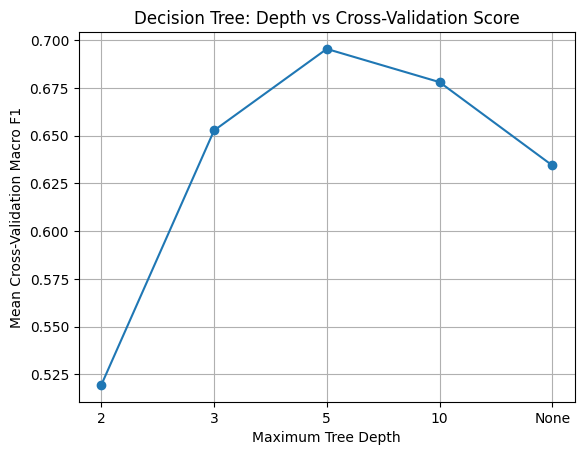

In [20]:
#Graph:

depth_labels = [str(d) for d in depth_values]

plt.plot(depth_labels, tree_accuracies, marker='o')
plt.xlabel('Maximum Tree Depth')
plt.ylabel('Mean Cross-Validation Macro F1')
plt.title('Decision Tree: Depth vs Cross-Validation Score')
plt.grid(True)
plt.show()


In [21]:
#Step 4: Logistic Regression

In [22]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train_scaled, y_train)

print("Logistic Regression training accuracy:",
      log_model.score(X_train_scaled, y_train))


Logistic Regression training accuracy: 0.7766176470588235


In [23]:
probabilities = log_model.predict_proba(X_train_scaled[:5])

print("Classes:", log_model.classes_)
print("\nProbabilities for first 5 training rows:")
print(np.round(probabilities, 3))


Classes: ['Mild Deficit' 'Moderate Debt' 'Optimal Recovery' 'Severe Sleep Debt']

Probabilities for first 5 training rows:
[[0.599 0.122 0.279 0.   ]
 [0.277 0.716 0.005 0.002]
 [0.22  0.769 0.011 0.   ]
 [0.615 0.284 0.101 0.   ]
 [0.198 0.003 0.798 0.   ]]


In [24]:
#Step 5: Model Evaluation and Comparison

In [25]:
# Best KNN
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train_scaled, y_train)
y_pred_knn = knn.predict(X_test_scaled)

# Best Decision Tree
tree = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
tree.fit(X_train, y_train)
y_pred_tree = tree.predict(X_test)

# Logistic Regression
log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train_scaled, y_train)
y_pred_log = log_model.predict(X_test_scaled)

print("Final models trained successfully!")


Final models trained successfully!


In [26]:

from sklearn.metrics import confusion_matrix, classification_report

models = {
    f"KNN (K={best_k})": (knn, X_test_scaled, y_pred_knn),
    f"Decision Tree (depth={best_depth})": (tree, X_test, y_pred_tree),
    "Logistic Regression": (log_model, X_test_scaled, y_pred_log)
}

for name, (model, X_data, predictions) in models.items():
    print("\n", name)
    print("Accuracy:", accuracy_score(y_test, predictions))
    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, predictions))
    print("\nClassification Report:")
    print(classification_report(y_test, predictions, zero_division=0))



 KNN (K=3)
Accuracy: 0.6394117647058823

Confusion Matrix:
[[217 115  69   0]
 [167 698   8  20]
 [133  14 130   0]
 [  4  83   0  42]]

Classification Report:
                   precision    recall  f1-score   support

     Mild Deficit       0.42      0.54      0.47       401
    Moderate Debt       0.77      0.78      0.77       893
 Optimal Recovery       0.63      0.47      0.54       277
Severe Sleep Debt       0.68      0.33      0.44       129

         accuracy                           0.64      1700
        macro avg       0.62      0.53      0.56      1700
     weighted avg       0.65      0.64      0.64      1700


 Decision Tree (depth=5)
Accuracy: 0.7423529411764705

Confusion Matrix:
[[256  81  64   0]
 [138 724   5  26]
 [ 81   1 195   0]
 [  0  42   0  87]]

Classification Report:
                   precision    recall  f1-score   support

     Mild Deficit       0.54      0.64      0.58       401
    Moderate Debt       0.85      0.81      0.83       893
 Optimal Re

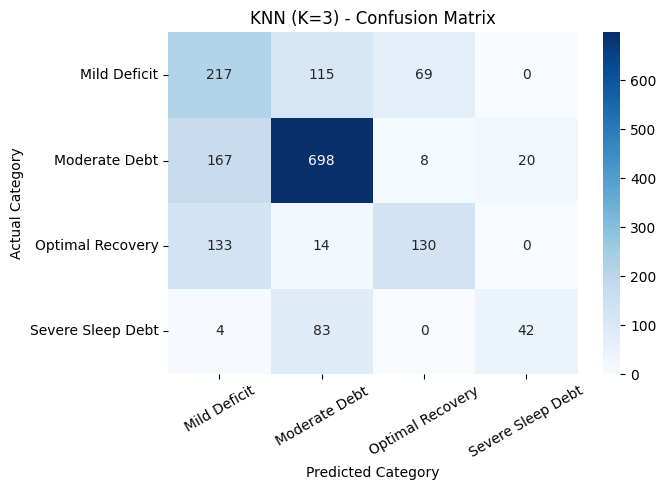

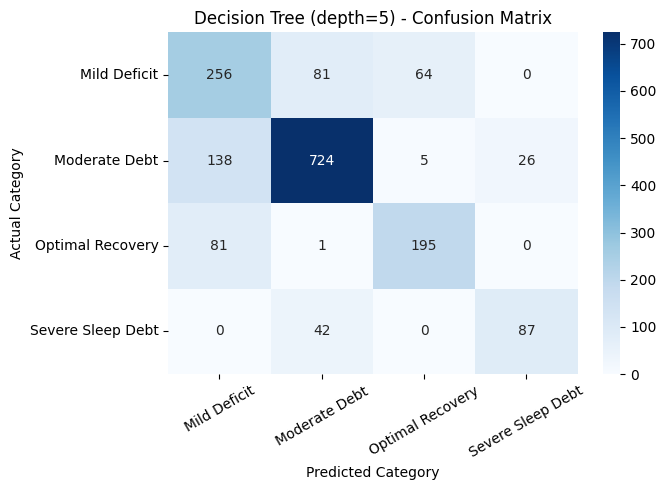

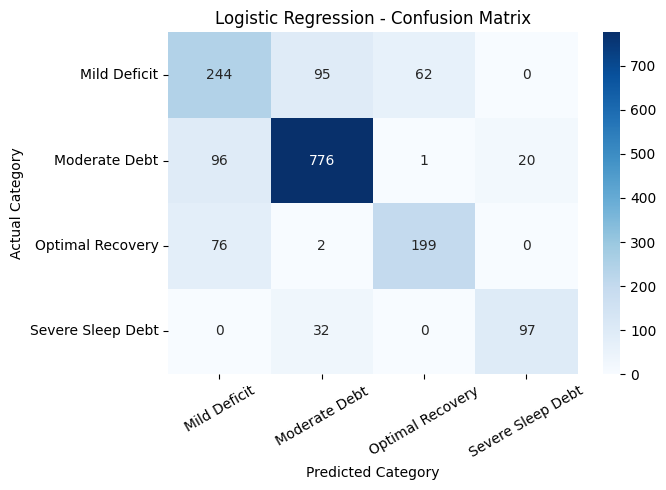

In [27]:

for name, (model, X_data, predictions) in models.items():
    cm = confusion_matrix(y_test, predictions, labels=model.classes_)

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=model.classes_,
        yticklabels=model.classes_
    )

    plt.title(name + ' - Confusion Matrix')
    plt.xlabel('Predicted Category')
    plt.ylabel('Actual Category')
    plt.xticks(rotation=30)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()


In [28]:

results = []

for name, (model, X_data, predictions) in models.items():
    report = classification_report(
        y_test, predictions, output_dict=True, zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": report["macro avg"]["precision"],
        "Recall": report["macro avg"]["recall"],
        "F1": report["macro avg"]["f1-score"]
    })

comparison = pd.DataFrame(results)

display(comparison.round(4))


,Model,Accuracy,Precision,Recall,F1
0,KNN (K=3),0.6394,0.6222,0.5294,0.5555
1,Decision Tree (depth=5),0.7424,0.7253,0.7069,0.7140
2,Logistic Regression,0.7741,0.7581,0.7370,0.7469


In [29]:
#Step 6: Evaluations:
#Which Model Is Best and Why?

#Logistic Regression performed best among the three models.
#It achieved 77.41% accuracy and 74.69% macro F1-score.
#Decision Tree achieved 74.24% accuracy and 71.40% macro F1-score.
#KNN achieved 63.94% accuracy and 55.55% macro F1-score.

#Logistic Regression is selected as the best model because it
#achieved the highest accuracy, precision, recall, and macro F1-score.

#The results are more realistic after removing suspected target leakage features.
#The final comparison is based on test results after selecting model parameters
#using cross-validation on the training data.

In [30]:
# - Which mistake is worse for YOUR problem: a false positive
#    or a false negative? So which metric matters more
#   (precision or recall)?

#For my sleep debt problem, I consider a false negative for Severe Sleep Debt more concerning.
#It means the model misses a person who actually belongs to the severe category.
#A false positive means the model incorrectly predicts Severe Sleep Debt
#for someone who belongs to another category.
#Therefore, recall (TP/(TP+FN)) for Severe Sleep Debt is an important metric
#because it measures how many actual severe cases the model correctly identifies.

In [31]:
#Where does the best model make mistakes?

#Logistic Regression is the best model based on the corrected comparison.

#Its confusion matrix shows that some categories are incorrectly classified.

#For Mild Deficit, 95 samples were predicted as Moderate Debt.
#For Moderate Debt, 96 samples were predicted as Mild Deficit.
#For Optimal Recovery, 76 samples were predicted as Mild Deficit.
#For Severe Sleep Debt, 32 samples were predicted as Moderate Debt.
# ""Confusion Matrix:
# [[244  95  62   0]
#  [ 96 776   1  20]
#  [ 76   2 199   0]
#  [  0  32   0  97]]""
#(copied from above outputs)

#The model struggles particularly with distinguishing Mild Deficit from Moderate Debt.
#It also misses 32 actual Severe Sleep Debt cases by predicting them as Moderate Debt.
#Although Logistic Regression performs best overall, these errors show that the model is not perfect.

In [33]:
#Extra Work:(Bonus);

#Is Accuracy Alone Misleading?

#Accuracy alone may be misleading when the target classes
#are imbalanced (like in SleepDebt we have four target classes: Mild Deficit, Moderate Debt, Optimal Recovery, Severe Sleep Debt)
#because it does not show how well the model performs on each class.
#(Classes Inbalance Proof):
#The class percentages are printed in the Target Class Distribution section.
# Class percentages:
# sleep_debt_category
# Moderate Debt        52.49
# Mild Deficit         23.58
# Optimal Recovery     16.32
# Severe Sleep Debt     7.61 (copied from above cells)
#Macro F1-score is useful because it gives each class equal weight.